In [128]:
import pandas as pd 
import numpy as np
import matplotlib as plt
import seaborn as sns 
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,r2_score
import scipy.stats as  stats

In [129]:

df = pd.read_csv ("CAR DETAILS FROM CAR DEKHO.csv")

In [130]:
df.head()


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [4]:
df.tail()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
4335,Hyundai i20 Magna 1.4 CRDi (Diesel),2014,409999,80000,Diesel,Individual,Manual,Second Owner
4336,Hyundai i20 Magna 1.4 CRDi,2014,409999,80000,Diesel,Individual,Manual,Second Owner
4337,Maruti 800 AC BSIII,2009,110000,83000,Petrol,Individual,Manual,Second Owner
4338,Hyundai Creta 1.6 CRDi SX Option,2016,865000,90000,Diesel,Individual,Manual,First Owner
4339,Renault KWID RXT,2016,225000,40000,Petrol,Individual,Manual,First Owner


In [5]:
df. shape

(4340, 8)

In [6]:
df.size


34720

In [7]:
df.columns


Index(['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type',
       'transmission', 'owner'],
      dtype='str')

In [8]:
df.dtypes

name               str
year             int64
selling_price    int64
km_driven        int64
fuel               str
seller_type        str
transmission       str
owner              str
dtype: object

In [9]:
df.memory_usage()

Index               132
name             141465
year              34720
selling_price     34720
km_driven         34720
fuel              60573
seller_type       74756
transmission      62104
owner             84346
dtype: int64

In [10]:
#### data cleaning
df.isnull().sum()


name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

In [11]:
(df.isnull().sum()/ len(df)) * 100

name             0.0
year             0.0
selling_price    0.0
km_driven        0.0
fuel             0.0
seller_type      0.0
transmission     0.0
owner            0.0
dtype: float64

In [12]:
df.duplicated().sum()

np.int64(763)

In [13]:
df.shape

(4340, 8)

In [14]:
df.dtypes

name               str
year             int64
selling_price    int64
km_driven        int64
fuel               str
seller_type        str
transmission       str
owner              str
dtype: object

In [15]:
df["fuel"].unique()

<ArrowStringArray>
['Petrol', 'Diesel', 'CNG', 'LPG', 'Electric']
Length: 5, dtype: str

In [16]:
df["seller_type"].unique()

<ArrowStringArray>
['Individual', 'Dealer', 'Trustmark Dealer']
Length: 3, dtype: str

In [17]:
df["transmission"].unique()

<ArrowStringArray>
['Manual', 'Automatic']
Length: 2, dtype: str

In [18]:
df["owner"].unique()

<ArrowStringArray>
[         'First Owner',         'Second Owner', 'Fourth & Above Owner',
          'Third Owner',       'Test Drive Car']
Length: 5, dtype: str

In [19]:
df_clean = df

In [20]:
df_clean["year"] = df ["year"].astype(int)
df_clean["selling_price"] = df["selling_price"].astype(float)

In [21]:
df["year"] = df["year"].astype(int)

df["selling_price"] = df["selling_price"].astype(float)


In [22]:
df["car_age"] = 2026 - df["year"]


In [23]:
###datformation 
df["year"] = df["year"].astype(int)
df["selling_price"] = df["selling_price"].astype(float)

In [24]:
df["car_age"] = 2026 - df["year"]

In [25]:
df["car_age"] = 2026 - df["year"]


In [26]:
df.describe()

,year,selling_price,km_driven,car_age
count,4340.000000,4.340000e+03,4340.000000,4340.000000
mean,2013.090783,5.041273e+05,66215.777419,12.909217
std,4.215344,5.785487e+05,46644.102194,4.215344
min,1992.000000,2.000000e+04,1.000000,6.000000
25%,2011.000000,2.087498e+05,35000.000000,10.000000
50%,2014.000000,3.500000e+05,60000.000000,12.000000
75%,2016.000000,6.000000e+05,90000.000000,15.000000
max,2020.000000,8.900000e+06,806599.000000,34.000000


In [27]:
import warnings
warnings.filterwarnings("ignore")

In [28]:
warnings.filterwarnings("ignore", category=FutureWarning)

In [29]:
df.describe(include="object")

,name,fuel,seller_type,transmission,owner
count,4340,4340,4340,4340,4340
unique,1491,5,3,2,5
top,Maruti Swift Dzire VDI,Diesel,Individual,Manual,First Owner
freq,69,2153,3244,3892,2832


In [30]:
Q1 = df["selling_price"].quantile(0.25)
Q3 = df["selling_price"].quantile(0.75)

IQR = Q3 - Q1

Lower = Q1 - 1.5 * IQR
Upper = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Boundary:", Lower)
print("Upper Boundary:", Upper)

Q1: 208749.75
Q3: 600000.0
IQR: 391250.25
Lower Boundary: -378125.625
Upper Boundary: 1186875.375


In [31]:
outliers = df[
    (df["selling_price"] < Lower)| 
    (df["selling_price"] > Upper)]
print("Total outliers:", len(outliers))
outliers.head()

Total outliers: 271


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,car_age
12,Toyota Corolla Altis 1.8 VL CVT,2018,1650000.0,25000,Petrol,Dealer,Automatic,First Owner,8
25,Toyota Corolla Altis 1.8 VL CVT,2018,1650000.0,25000,Petrol,Dealer,Automatic,First Owner,8
27,Hyundai Venue SX Opt Diesel,2019,1195000.0,5000,Diesel,Dealer,Manual,First Owner,7
29,Jaguar XF 2.2 Litre Luxury,2014,1964999.0,28000,Diesel,Dealer,Automatic,First Owner,12
30,Mercedes-Benz New C-Class 220 CDI AT,2013,1425000.0,59000,Diesel,Dealer,Automatic,First Owner,13


In [32]:
df["selling_price_clean"] = df["selling_price"].clip(
    lower =Lower,
    upper =Upper
    )

In [33]:
df[["selling_price", "selling_price_clean"]].head(10)

,selling_price,selling_price_clean
0,60000.0,60000.0
1,135000.0,135000.0
2,600000.0,600000.0
3,250000.0,250000.0
4,450000.0,450000.0
5,140000.0,140000.0
6,550000.0,550000.0
7,240000.0,240000.0
8,850000.0,850000.0
9,365000.0,365000.0


In [34]:
df_clean = df[(df["selling_price"] >= Lower)& (df["selling_price"]<= Upper)
    ]

In [35]:
print("original rows",len(df))
print("Rows after removing outliers", len(df_clean))
print("Removed rows", len(df) - len(df_clean))

original rows 4340
Rows after removing outliers 4069
Removed rows 271


In [36]:
mean_price = df_clean["selling_price"].mean()
median_price = df_clean["selling_price"].median()
mode_price = df_clean["selling_price"].mode()[0]
print("mean", mean_price)
print ("median", median_price)
print("mode", mode_price)

mean 392378.60260506265
median 340000.0
mode 300000.0


In [37]:
varieance = df_clean["selling_price"].var()
std_dev = df_clean["selling_price"].std()
print("Varieance:", varieance)
print("Standard Deviation:", std_dev)

Varieance: 61559964840.995186
Standard Deviation: 248112.80668477228


In [38]:
skewness = df_clean["selling_price"].skew()
kurtosis = df_clean["selling_price"].kurt()
print("skewness",skewness)
print("kurtosis", kurtosis)

skewness 0.7858460799950518
kurtosis -0.027054105215731372


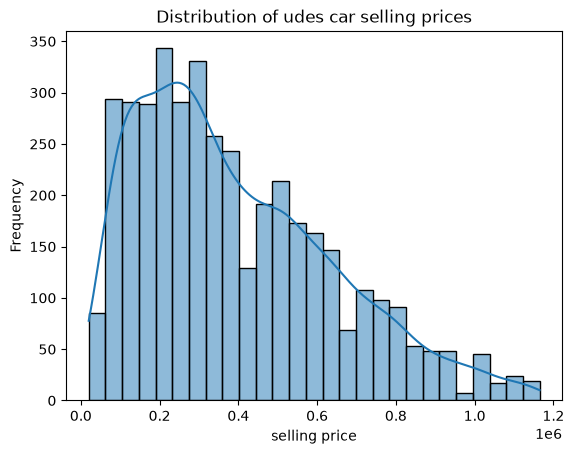

In [39]:
sns.histplot(df_clean["selling_price"], kde=True)
plt.title("Distribution of udes car selling prices")
plt.xlabel("selling price")
plt.ylabel("Frequency")
plt.show()

In [40]:
correlation = df_clean.select_dtypes(include="number").corr()
print(correlation)

                         year  selling_price  km_driven   car_age  \
year                 1.000000       0.625484  -0.402742 -1.000000   
selling_price        0.625484       1.000000  -0.227147 -0.625484   
km_driven           -0.402742      -0.227147   1.000000  0.402742   
car_age             -1.000000      -0.625484   0.402742  1.000000   
selling_price_clean  0.625484       1.000000  -0.227147 -0.625484   

                     selling_price_clean  
year                            0.625484  
selling_price                   1.000000  
km_driven                      -0.227147  
car_age                        -0.625484  
selling_price_clean             1.000000  


<Axes: >

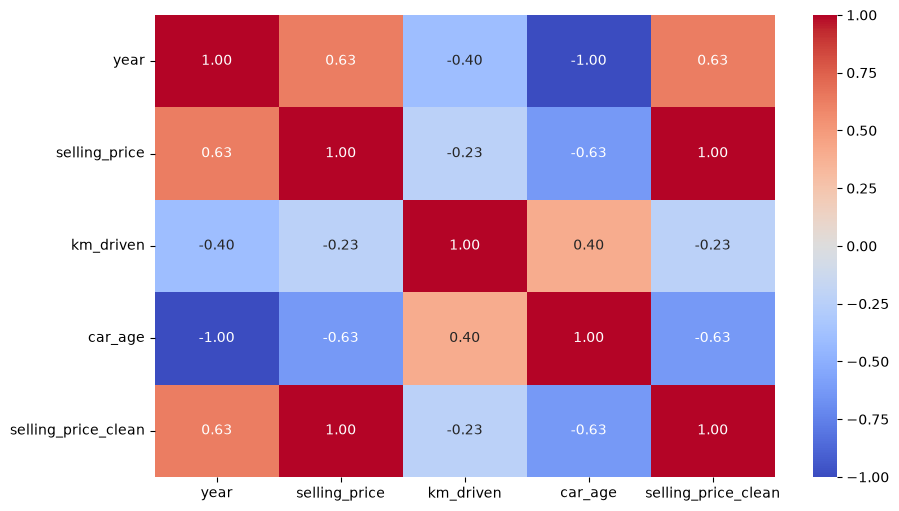

In [41]:
plt.figure(figsize=(10,6))
sns.heatmap(correlation,annot=True,cmap="coolwarm",fmt=".2f")

Text(0.5, 1.0, 'car year vs selling price')

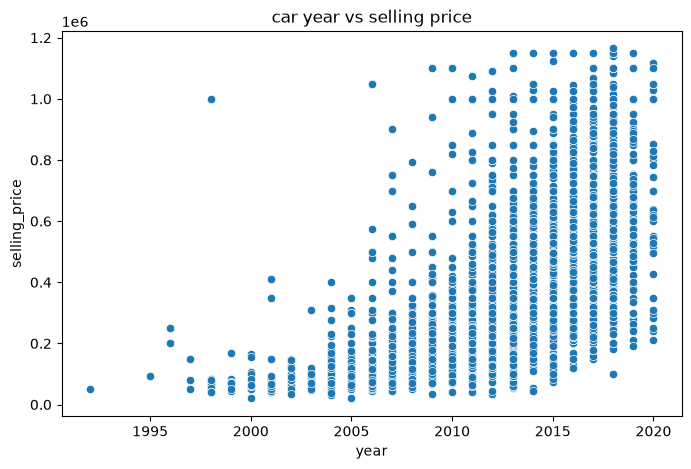

In [42]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df_clean, x="year",y="selling_price")
plt.title("car year vs selling price")
                

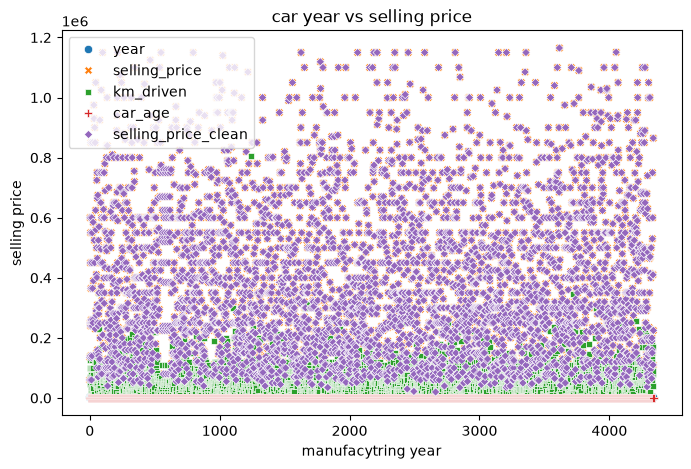

In [43]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df_clean)
x="year"
y="selling_price"
alpha=0.3,

plt.title("car year vs selling price")
plt.xlabel("manufacytring year")
plt.ylabel("selling price")
plt.show()

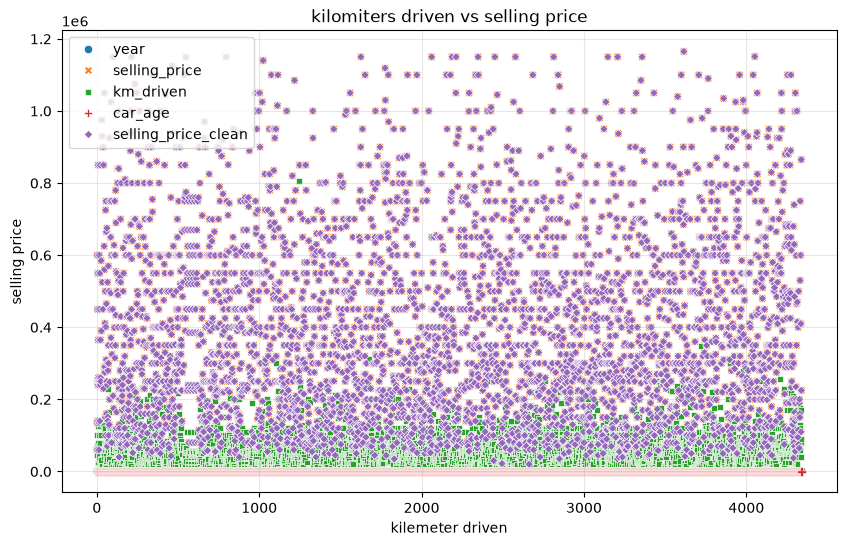

In [44]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=df_clean),
x="km_driven",
y= "selling_price",
alpha=0.3,
plt.title("kilomiters driven vs selling price")
plt.xlabel("kilemeter driven")
plt.ylabel("selling price")
plt.grid(alpha=0.3)
plt.show()


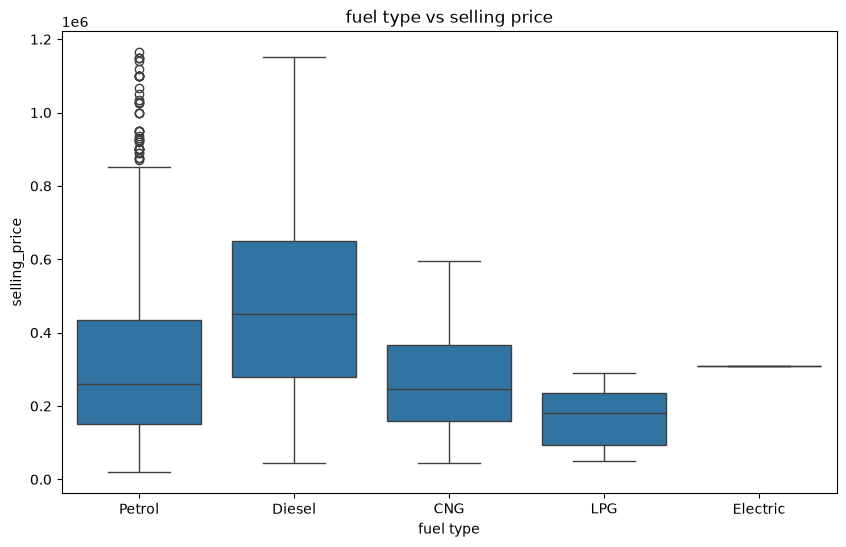

In [45]:
plt.figure(figsize=(10,6))
sns.boxplot(data=df_clean, x="fuel", y="selling_price")
plt.title("fuel type vs selling price")
plt.xlabel("fuel type")
plt.ylabel("selling_price")
plt.show()

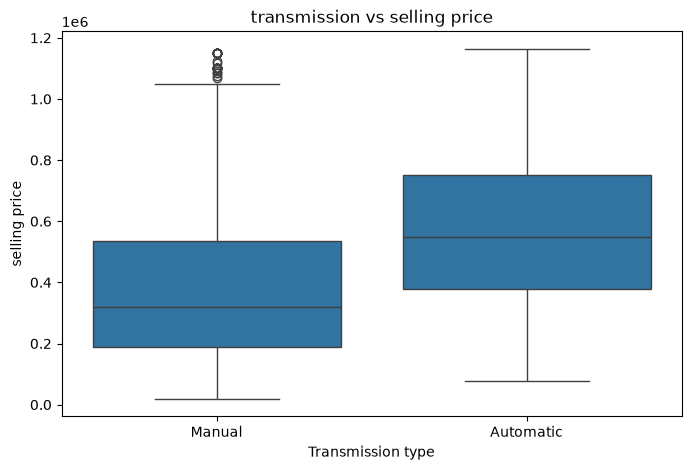

In [46]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df_clean, x="transmission", y="selling_price")
plt.title("transmission vs selling price")
plt.xlabel("Transmission type")
plt.ylabel("selling price")
plt.show()

In [47]:
df_clean.groupby("transmission")["selling_price"].mean().sort_values(ascending=False)

transmission
Automatic    589459.116732
Manual       379091.694911
Name: selling_price, dtype: float64

In [48]:
owner_price = df_clean.groupby("owner")["selling_price"].mean().sort_values(ascending=False)
print(owner_price)

owner
Test Drive Car          871999.785714
First Owner             449728.213626
Second Owner            308437.656192
Third Owner             231874.479592
Fourth & Above Owner    173901.197531
Name: selling_price, dtype: float64


<function matplotlib.pyplot.show(close=None, block=None)>

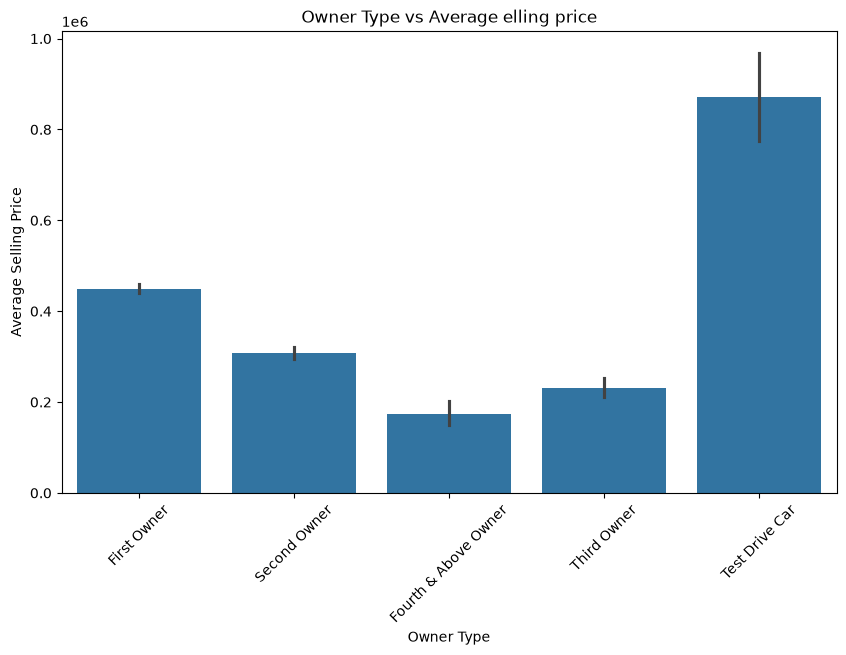

In [49]:
plt.figure(figsize=(10,6))
sns.barplot(data=df_clean, x="owner", y="selling_price", estimator="mean")
plt.title("Owner Type vs Average elling price")
plt.xlabel("Owner Type")
plt.ylabel("Average Selling Price")
plt.xticks(rotation=45)
plt.show
        

In [50]:
df_clean["car_age"] = 2026- df_clean["year"]

In [51]:
df_clean[["year", "car_age"]].head(10)

,year,car_age
0,2007,19
1,2007,19
2,2012,14
3,2017,9
4,2014,12
5,2007,19
6,2016,10
7,2014,12
8,2015,11
9,2017,9


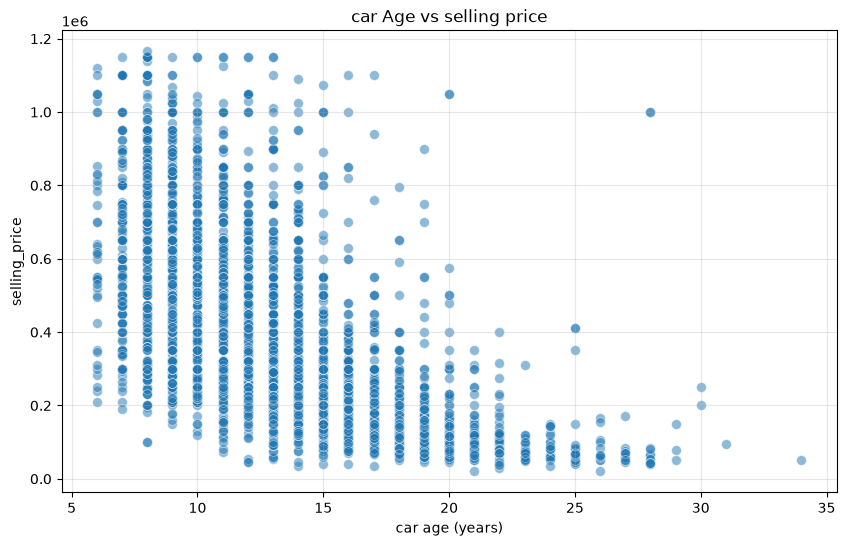

In [52]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=df_clean, 
x="car_age",
y="selling_price",
alpha=0.5, 
s=50)
plt.title("car Age vs selling price")
plt.xlabel("car age (years)")
plt.ylabel("selling_price")
plt.grid(alpha=0.3)
plt.show()

In [53]:
df_clean.groupby("car_age")["selling_price"].mean().sort_index()

car_age
6     650536.536585
7     622503.187097
8     623697.328947
9     574280.835351
10    514050.239645
11    487524.470588
12    429760.072254
13    378188.042614
14    328094.228288
15    277213.438202
16    238548.406926
17    213715.757895
18    174201.331034
19    162828.350746
20    157799.945455
21    109013.023529
22    121749.976190
23     86565.217391
24     90714.285714
25    117649.900000
26     81500.000000
27     73500.000000
28    214000.000000
29     93000.000000
30    225000.000000
31     95000.000000
34     50000.000000
Name: selling_price, dtype: float64

In [54]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df_clean["fuel_encoded"] = le.fit_transform(df_clean["fuel"])
df_clean[["fuel","fuel_encoded"]].head(10)

,fuel,fuel_encoded
0,Petrol,4
1,Petrol,4
2,Diesel,1
3,Petrol,4
4,Diesel,1
5,Petrol,4
6,Petrol,4
7,Petrol,4
8,Petrol,4
9,CNG,0


In [55]:
from sklearn.preprocessing import LabelEncoder

le_seller = LabelEncoder()
le_transmission = LabelEncoder()
le_owner = LabelEncoder()
df_clean["seller_encoded"] = le_seller.fit_transform(df_clean["seller_type"])
df_clean["transmission_encoded"] = le_transmission.fit_transform(df_clean["transmission"])
df_clean["owner_encoded"] = le_owner.fit_transform(df_clean["owner"])    

In [56]:
df_clean[["seller_type", "seller_encoded", "transmission", "transmission_encoded", "owner", "owner_encoded"]].head(10)

,seller_type,seller_encoded,transmission,transmission_encoded,owner,owner_encoded
0,Individual,1,Manual,1,First Owner,0
1,Individual,1,Manual,1,First Owner,0
2,Individual,1,Manual,1,First Owner,0
3,Individual,1,Manual,1,First Owner,0
4,Individual,1,Manual,1,Second Owner,2
5,Individual,1,Manual,1,First Owner,0
6,Individual,1,Manual,1,First Owner,0
7,Individual,1,Manual,1,Second Owner,2
8,Individual,1,Manual,1,First Owner,0
9,Individual,1,Manual,1,First Owner,0


In [57]:
x = df_clean.drop("selling_price", axis=1)
y = df_clean["selling_price"]
print(x.head())
print (y.head())

                       name  year  km_driven    fuel seller_type transmission  \
0             Maruti 800 AC  2007      70000  Petrol  Individual       Manual   
1  Maruti Wagon R LXI Minor  2007      50000  Petrol  Individual       Manual   
2      Hyundai Verna 1.6 SX  2012     100000  Diesel  Individual       Manual   
3    Datsun RediGO T Option  2017      46000  Petrol  Individual       Manual   
4     Honda Amaze VX i-DTEC  2014     141000  Diesel  Individual       Manual   

          owner  car_age  selling_price_clean  fuel_encoded  seller_encoded  \
0   First Owner       19              60000.0             4               1   
1   First Owner       19             135000.0             4               1   
2   First Owner       14             600000.0             1               1   
3   First Owner        9             250000.0             4               1   
4  Second Owner       12             450000.0             1               1   

   transmission_encoded  owner_encoded

In [58]:
print("x shape", x.shape)
print("y shape", y.shape)

x shape (4069, 13)
y shape (4069,)


In [59]:
from sklearn.model_selection import train_test_split

In [60]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2, random_state= 42)


In [61]:
x.select_dtypes(include="object").columns

Index(['name', 'fuel', 'seller_type', 'transmission', 'owner'], dtype='str')

In [62]:
x = df_clean.drop(["selling_price","name"], axis=1)
x = pd.get_dummies(x, drop_first=True, dtype=int)
y = df_clean["selling_price"]

In [63]:
x.dtypes

year                              int64
km_driven                         int64
car_age                           int64
selling_price_clean             float64
fuel_encoded                      int64
seller_encoded                    int64
transmission_encoded              int64
owner_encoded                     int64
fuel_Diesel                       int64
fuel_Electric                     int64
fuel_LPG                          int64
fuel_Petrol                       int64
seller_type_Individual            int64
seller_type_Trustmark Dealer      int64
transmission_Manual               int64
owner_Fourth & Above Owner        int64
owner_Second Owner                int64
owner_Test Drive Car              int64
owner_Third Owner                 int64
dtype: object

In [64]:
x = pd.get_dummies(x,drop_first=True, dtype=int)

In [65]:
c = df_clean.drop(columns=["selling_price", "name"])
y = df_clean["selling_price"]

In [66]:
import pandas as pd
x = pd.get_dummies(x, drop_first=True,dtype=int)

In [67]:
print(x.select_dtypes(include="object").columns)

Index([], dtype='str')


In [68]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train,y_test = train_test_split(
    x,y,test_size=0.2,random_state=42)

In [69]:
print(x.select_dtypes(include="object").columns)

Index([], dtype='str')


In [70]:
print("x_train", x_train.shape)
print("x_test", x_test.shape)
print("y_train", y_train.shape)
print("y_test", y_test.shape)

x_train (3255, 19)
x_test (814, 19)
y_train (3255,)
y_test (814,)


In [71]:
from sklearn.linear_model import LinearRegression

In [72]:
model = LinearRegression()

In [73]:
model.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](19,)","[ 0., 0.,-0.,..., 0., 0.,-0.]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](19,)","['year','km_driven','car_age',...,'owner_Second Owner', 'owner_Test Drive Car','owner_Third Owner']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1.417e-06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,19
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)


In [74]:
model.get_params()

{'copy_X': True,
 'fit_intercept': True,
 'n_jobs': None,
 'positive': False,
 'tol': 1e-06}

In [75]:
model.coef_

array([ 6.85717926e-10,  4.99880698e-14, -6.85717921e-10,  1.00000000e+00,
        2.23674115e-08,  1.38352657e-07, -8.18887953e-09,  5.91727556e-09,
        7.89514595e-08, -6.88609387e-10, -1.49869750e-08, -2.56147606e-09,
       -1.61840460e-07,  1.50096559e-07, -8.18887953e-09, -2.45390829e-09,
        9.79208916e-11,  2.49789965e-08, -1.66904119e-08])

In [76]:
model.intercept_

np.float64(-1.4168908819556236e-06)

In [77]:
model.n_features_in_

19

In [78]:
print("intercept", model.intercept_)
print("coefficients", model.coef_)
print("number of features", model.n_features_in_)

intercept -1.4168908819556236e-06
coefficients [ 6.85717926e-10  4.99880698e-14 -6.85717921e-10  1.00000000e+00
  2.23674115e-08  1.38352657e-07 -8.18887953e-09  5.91727556e-09
  7.89514595e-08 -6.88609387e-10 -1.49869750e-08 -2.56147606e-09
 -1.61840460e-07  1.50096559e-07 -8.18887953e-09 -2.45390829e-09
  9.79208916e-11  2.49789965e-08 -1.66904119e-08]
number of features 19


In [79]:
y_pred = model.predict(x_test)

In [80]:
print(y_pred[:10])

[430000.         434999.00000001 129999.99999999 350999.99999999
 599999.99999998 195000.00000001 799999.99999996 245000.00000001
 300000.00000003 210000.00000003]


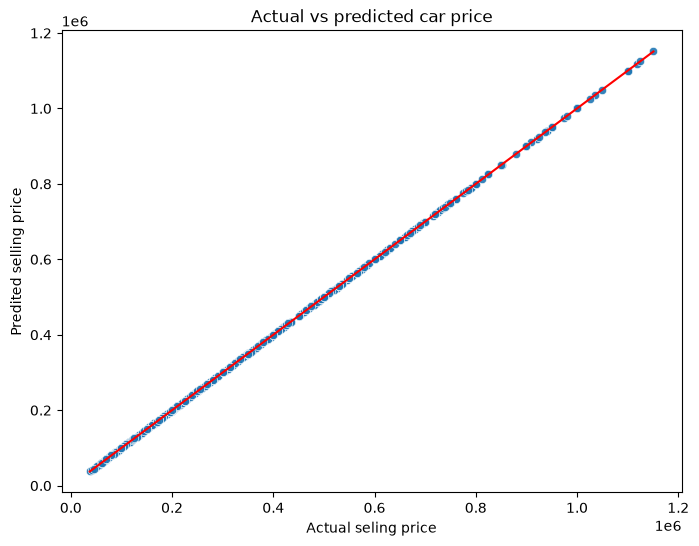

In [81]:
plt.figure(figsize=(8,6))
sns.scatterplot(x=y_test,y=y_pred,alpha=0.9)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(),y_test.max()],color="red")
plt.xlabel("Actual seling price")
plt.ylabel("Predited selling price")
plt.title("Actual vs predicted car price")
plt.show()

In [82]:
residuals = y_test - y_pred
print(residuals.head(10))


3960    5.238689e-10
3611   -5.064066e-09
1585    6.955815e-09
1205    9.895302e-09
2608    2.305023e-08
2136   -8.411007e-09
186     3.597233e-08
1154   -1.073931e-08
1281   -2.741581e-08
2575   -2.724119e-08
Name: selling_price, dtype: float64


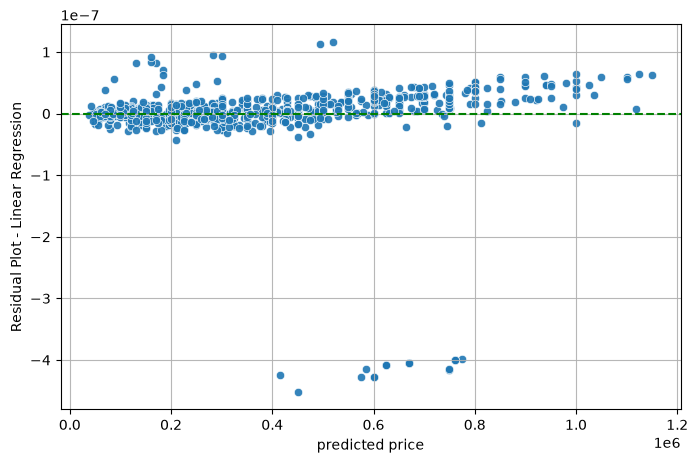

In [83]:
plt.figure(figsize=(8,5))
sns.scatterplot(x=y_pred,y=residuals,alpha=0.9)
plt.axhline(y=0, color="green", linestyle="--")
plt.xlabel("predicted price")
plt.ylabel("Residual Plot - Linear Regression")
plt.grid(alpha=0.9)
plt.show()

In [84]:
fuel_price= df_clean.groupby("fuel")["selling_price"].mean().sort_values(ascending=False)
print("fuel_price")

fuel_price


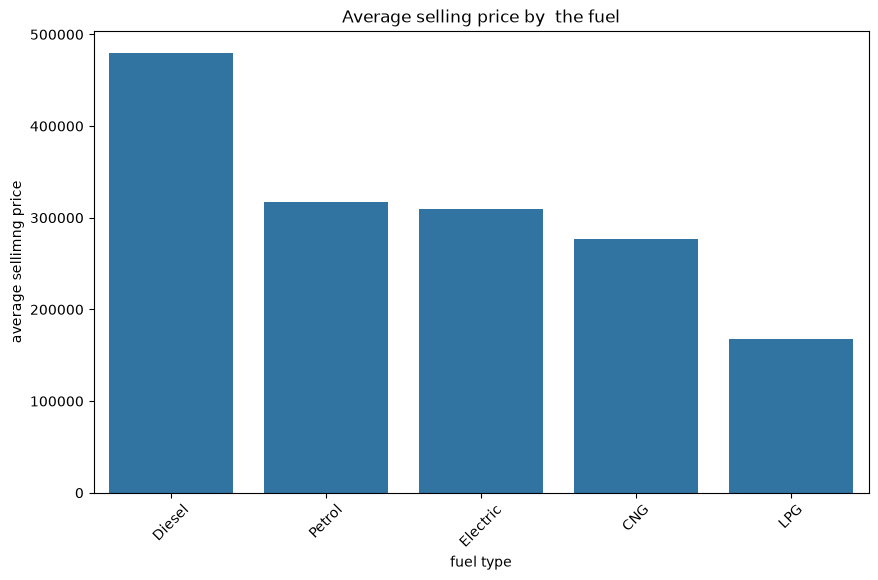

In [85]:
plt.figure(figsize=(10,6))
sns.barplot(x=fuel_price.index, y=fuel_price.values)
plt.title("Average selling price by  the fuel")
plt.xlabel("fuel type")
plt.ylabel("average sellimng price")
plt.xticks(rotation=45)
plt.show()

In [86]:
transmission_price = df_clean.groupby("transmission")["selling_price"].mean().sort_values(ascending=False)
print(transmission_price)

transmission
Automatic    589459.116732
Manual       379091.694911
Name: selling_price, dtype: float64


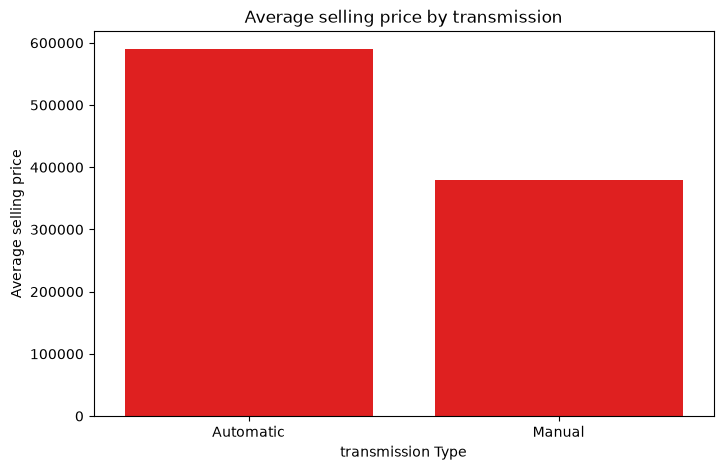

In [87]:
plt.figure(figsize=(8,5))
sns.barplot(x=transmission_price.index, y=transmission_price.values,color="red")
plt.title("Average selling price by transmission")
plt.xlabel("transmission Type")
plt.ylabel("Average selling price")
plt.show()

In [88]:
age_price = df_clean.groupby("car_age")["selling_price"].mean().sort_values()
print(age_price)

car_age
34     50000.000000
27     73500.000000
26     81500.000000
23     86565.217391
24     90714.285714
29     93000.000000
31     95000.000000
21    109013.023529
25    117649.900000
22    121749.976190
20    157799.945455
19    162828.350746
18    174201.331034
17    213715.757895
28    214000.000000
30    225000.000000
16    238548.406926
15    277213.438202
14    328094.228288
13    378188.042614
12    429760.072254
11    487524.470588
10    514050.239645
9     574280.835351
7     622503.187097
8     623697.328947
6     650536.536585
Name: selling_price, dtype: float64


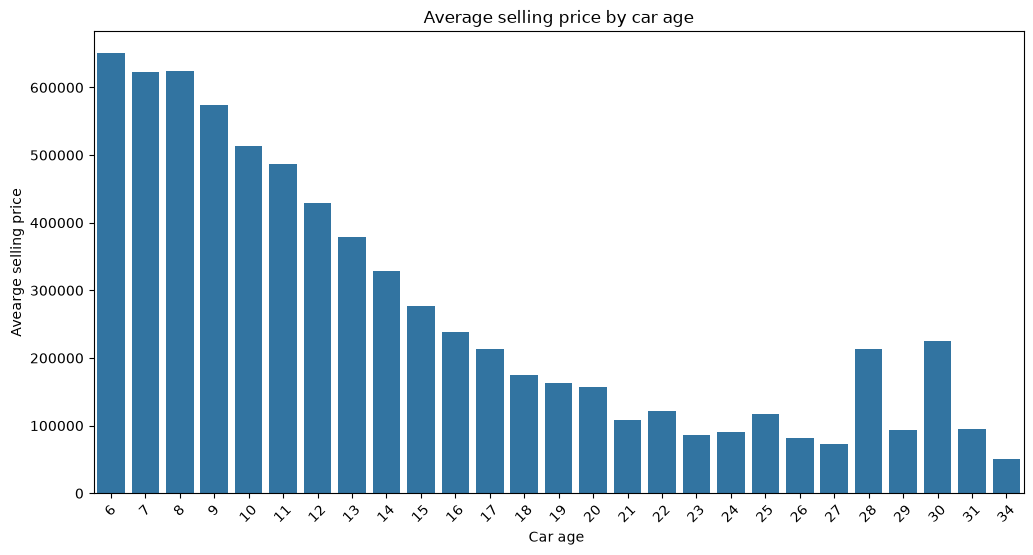

In [89]:
plt.figure(figsize=(12,6))
sns.barplot(x=age_price.index, y=age_price.values)
plt.title("Average selling price by car age")
plt.xlabel("Car age ")
plt.ylabel("Avearge selling price")
plt.xticks(rotation=45)
plt.show()

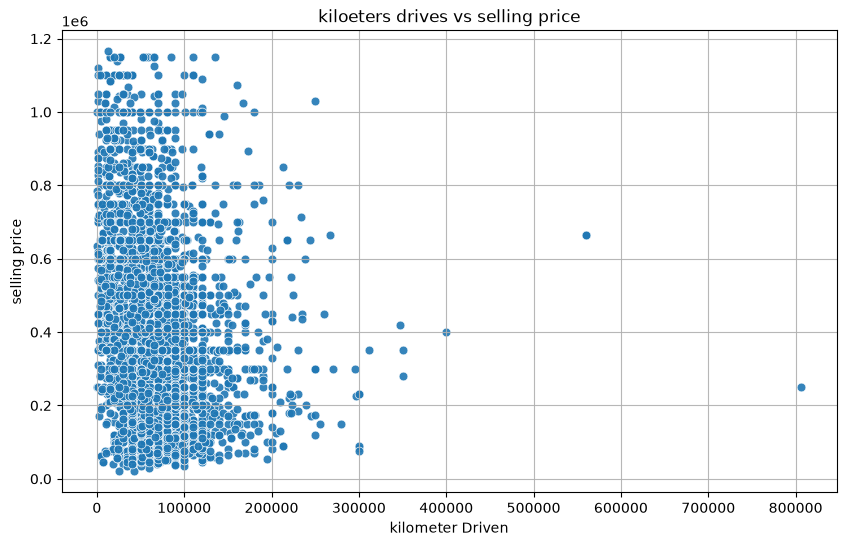

In [90]:
plt.figure(figsize=(10,6))
sns.scatterplot(
    data= df_clean,
    x="km_driven",
    y="selling_price",
    alpha=0.9,
    s=40
)
plt.title("kiloeters drives vs selling price")
plt.xlabel("kilometer Driven")
plt.ylabel("selling price")
plt.grid(alpha=0.9)
plt.show()
    

### comparison = pd.DataFrame({
    "Actual Price": y_test.values[:10],
   "Predicted Price": y_pred[:10]
})
print (comparison)

In [91]:
correlation = df_clean["km_driven"].corr(df_clean["selling_price"])
print("correlation", correlation)

correlation -0.22714704186062057


In [92]:
owner_price = df_clean.groupby("owner")["selling_price"].mean().sort_values(ascending=False)
print(owner_price)

owner
Test Drive Car          871999.785714
First Owner             449728.213626
Second Owner            308437.656192
Third Owner             231874.479592
Fourth & Above Owner    173901.197531
Name: selling_price, dtype: float64


In [93]:
seller_price = df_clean.groupby("seller_type")["selling_price"].mean().sort_values(ascending=False)
print(seller_price)

seller_type
Trustmark Dealer    684044.943820
Dealer              473363.372685
Individual          361592.612323
Name: selling_price, dtype: float64


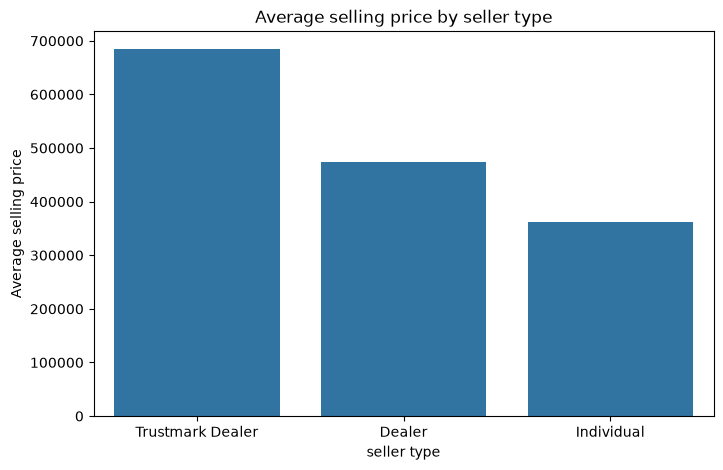

In [94]:
plt.figure(figsize=(8,5))
sns.barplot(x=seller_price.index, y=seller_price.values)
plt.title("Average selling price by seller type")
plt.xlabel("seller type")
plt.ylabel("Average selling price")
plt.show()

In [95]:
df_clean["brand"] = df_clean["name"].str.split().str[0]

In [96]:
brand_price = df_clean.groupby("brand")["selling_price"].mean().sort_values(ascending =False)
print(brand_price.head(10))

brand
Audi             1.008333e+06
Mercedes-Benz    8.692000e+05
Mitsubishi       8.400000e+05
BMW              8.200000e+05
Toyota           5.732243e+05
Mahindra         5.164851e+05
Honda            5.074793e+05
Ford             4.746577e+05
Volkswagen       4.627452e+05
Skoda            4.572462e+05
Name: selling_price, dtype: float64


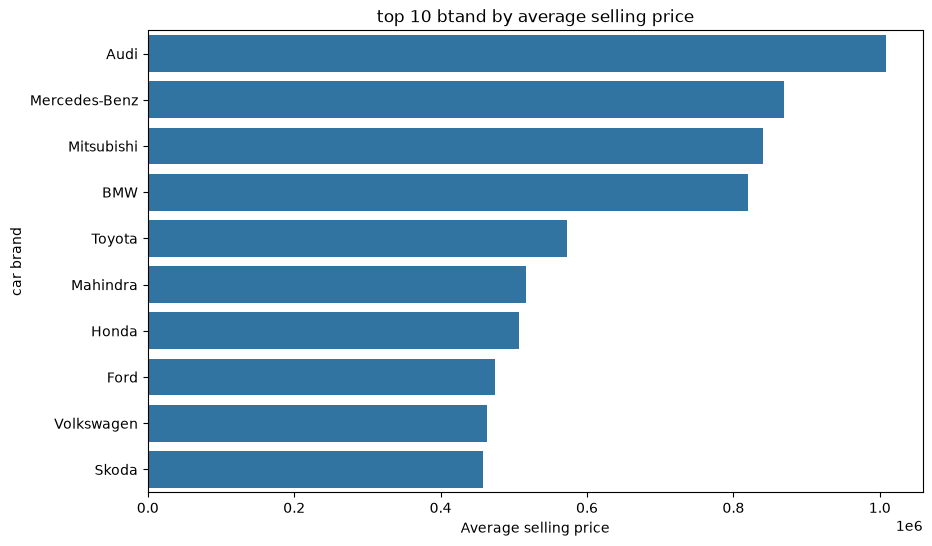

In [97]:
plt.figure(figsize=(10,6))
sns.barplot(x=brand_price.head(10).values, y=brand_price.head(10).index)
plt.title("top 10 btand by average selling price")
plt.xlabel("Average selling price")
plt.ylabel("car brand")
plt.show()

In [98]:
top_affortable = df_clean.nsmallest(10,"selling_price")

In [99]:
top_affordable = df_clean.nsmallest(10,"selling_price")
print(top_affortable[["name","year", "km_driven", "selling_price"]])

                       name  year  km_driven  selling_price
2662  Ford Ikon 1.6 ZXI NXt  2005      25000        20000.0
2495      Ford Ikon 1.4 ZXi  2000      42743        22000.0
2444          Maruti 800 EX  2004      60000        30000.0
1832        Tata Nano LX SE  2012      35000        35000.0
2849     Tata Nano Std BSII  2009      50000        35000.0
3206       OpelCorsa 1.4 GL  2002     100000        35000.0
4290         Maruti 800 Std  2004      90000        37500.0
137          Maruti 800 Std  1998      40000        40000.0
877           Tata Nano Std  2011      19000        40000.0
1350          Maruti 800 EX  2001      30000        40000.0


In [100]:
fuel_transmission = df_clean.groupby(["fuel", "transmission"])["selling_price"].mean().unstack()

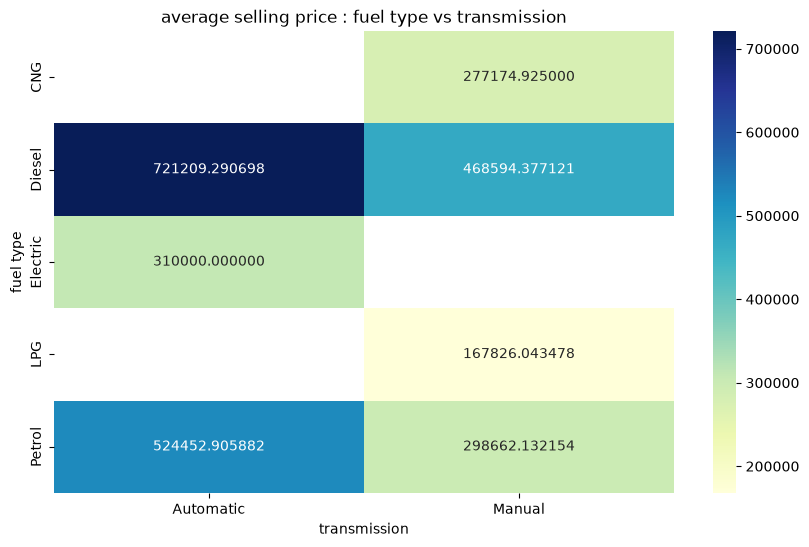

In [101]:
plt.figure(figsize=(10,6))
sns.heatmap(fuel_transmission,annot=True, fmt="0f", cmap="YlGnBu")
plt.title("average selling price : fuel type vs transmission")
plt.xlabel("transmission")
plt.ylabel("fuel type")
plt.show()

In [102]:
fuel_price = df_clean.groupby("fuel")["selling_price"].mean()
transmission_price = df_clean.groupby("transmission")["selling_price"].mean()
owner_price = df_clean.groupby("owner")["selling_price"].mean()
print("fuel_price")

print("\n transmission price")


fuel_price

 transmission price


In [103]:
print (fuel_price)

fuel
CNG         277174.925000
Diesel      479950.823837
Electric    310000.000000
LPG         167826.043478
Petrol      317010.330784
Name: selling_price, dtype: float64


In [104]:
print(transmission_price)

transmission
Automatic    589459.116732
Manual       379091.694911
Name: selling_price, dtype: float64


In [105]:
print(owner_price)

owner
First Owner             449728.213626
Fourth & Above Owner    173901.197531
Second Owner            308437.656192
Test Drive Car          871999.785714
Third Owner             231874.479592
Name: selling_price, dtype: float64


In [106]:
print("Highest fuel price")
print (fuel_price.idxmax(), fuel_price.max())
print("\n Highest transmission price")
print (transmission_price.idxmax(), transmission_price.max())
print ("\n Highest owner price")
print (owner_price.idxmax(), owner_price.max())
print ("\n Highest Brand price")
print ( brand_price.idxmax(), brand_price.max())

Highest fuel price
Diesel 479950.82383690536

 Highest transmission price
Automatic 589459.1167315175

 Highest owner price
Test Drive Car 871999.7857142857

 Highest Brand price
Audi 1008333.3333333334


In [107]:
import pandas as pd 


In [108]:
print(df_clean[["selling_price", "car_age", "km_driven"]].dtypes)
df_clean["seller_price"] = pd.to_numeric(df_clean["selling_price"], errors="coerce")
df_clean["car_age"] = pd.to_numeric(df_clean["car_age"], errors="coerce")
df_clean["km_driven"] = pd.to_numeric(df_clean["km_driven"], errors="coerce")

selling_price    float64
car_age            int64
km_driven          int64
dtype: object


In [109]:
print ("Total Cars", len(df_clean))
print ("average Selling price", df_clean["selling_price"].mean())
print ("Average car age", df_clean["car_age"].mean())
print ("Averaege kilomiters Driven", df_clean["km_driven"].mean())
print ("most comon fuel", df_clean ["fuel"].mode()[0])
print ("most common transmission", df_clean["transmission"].mode()[0])
print ("most common seller", df_clean ["seller_type"].mode()[0])

Total Cars 4069
average Selling price 392378.60260506265
Average car age 13.117965101990661
Averaege kilomiters Driven 67498.61710493978
most comon fuel Petrol
most common transmission Manual
most common seller Individual


In [110]:
print(df_clean.dtypes)


name                        str
year                      int64
selling_price           float64
km_driven                 int64
fuel                        str
seller_type                 str
transmission                str
owner                       str
car_age                   int64
selling_price_clean     float64
fuel_encoded              int64
seller_encoded            int64
transmission_encoded      int64
owner_encoded             int64
brand                    object
seller_price            float64
dtype: object


In [111]:
print (df_clean[["selling_price", "car_age", "km_driven"]].head())

   selling_price  car_age  km_driven
0        60000.0       19      70000
1       135000.0       19      50000
2       600000.0       14     100000
3       250000.0        9      46000
4       450000.0       12     141000


In [112]:
print(
    df_clean[["selling_price", "car_age", "km_driven"]]
    .map(type)
    .head()
)

     selling_price        car_age      km_driven
0  <class 'float'>  <class 'int'>  <class 'int'>
1  <class 'float'>  <class 'int'>  <class 'int'>
2  <class 'float'>  <class 'int'>  <class 'int'>
3  <class 'float'>  <class 'int'>  <class 'int'>
4  <class 'float'>  <class 'int'>  <class 'int'>


In [113]:
fuel_insights =df_clean.groupby("fuel")["selling_price"].agg(["count","mean","median","min", "max"]).round(2)
print(fuel_insights)

          count       mean    median       min        max
fuel                                                     
CNG          40  277174.92  247500.0   45000.0   595000.0
Diesel     1913  479950.82  450000.0   45000.0  1151000.0
Electric      1  310000.00  310000.0  310000.0   310000.0
LPG          23  167826.04  180000.0   50000.0   290000.0
Petrol     2092  317010.33  260000.0   20000.0  1165000.0


In [114]:
age_insights = df_clean.groupby("car_age")["selling_price"].agg(["count", "mean","median"]).round(2)
print(age_insights.head(15))

         count       mean    median
car_age                            
6           41  650536.54  619000.0
7          155  622503.19  600000.0
8          304  623697.33  624500.0
9          413  574280.84  550000.0
10         338  514050.24  517500.0
11         408  487524.47  470000.0
12         346  429760.07  400000.0
13         352  378188.04  350000.0
14         403  328094.23  285000.0
15         267  277213.44  235000.0
16         231  238548.41  211000.0
17         190  213715.76  180000.0
18         145  174201.33  140000.0
19         134  162828.35  125000.0
20         110  157799.95  107500.0


In [115]:
age_insights = df_clean.groupby("car_age")["selling_price"].agg(["count","mean","median"]).round(2)
print(age_insights.head(15))

         count       mean    median
car_age                            
6           41  650536.54  619000.0
7          155  622503.19  600000.0
8          304  623697.33  624500.0
9          413  574280.84  550000.0
10         338  514050.24  517500.0
11         408  487524.47  470000.0
12         346  429760.07  400000.0
13         352  378188.04  350000.0
14         403  328094.23  285000.0
15         267  277213.44  235000.0
16         231  238548.41  211000.0
17         190  213715.76  180000.0
18         145  174201.33  140000.0
19         134  162828.35  125000.0
20         110  157799.95  107500.0


In [116]:
seller_insight = df_clean.groupby("seller_type")["selling_price"].agg(["count","mean","median"]).round(2)
print(seller_insight)

                  count       mean    median
seller_type                                 
Dealer              864  473363.37  450000.0
Individual         3116  361592.61  300000.0
Trustmark Dealer     89  684044.94  670000.0


In [117]:
print(df_clean.dtypes)

name                        str
year                      int64
selling_price           float64
km_driven                 int64
fuel                        str
seller_type                 str
transmission                str
owner                       str
car_age                   int64
selling_price_clean     float64
fuel_encoded              int64
seller_encoded            int64
transmission_encoded      int64
owner_encoded             int64
brand                    object
seller_price            float64
dtype: object


In [118]:
print(df_clean[["selling_price","car_age", "km_driven"]].dtypes)

selling_price    float64
car_age            int64
km_driven          int64
dtype: object


In [119]:
print(df_clean["selling_price"].head(10))
print(df_clean["selling_price"].dtype)
print(type(df_clean["selling_price"].iloc[0]))

0     60000.0
1    135000.0
2    600000.0
3    250000.0
4    450000.0
5    140000.0
6    550000.0
7    240000.0
8    850000.0
9    365000.0
Name: selling_price, dtype: float64
float64
<class 'numpy.float64'>


In [120]:
print(df_clean["selling_price"].astype(float).mean())

392378.60260506265


In [121]:
print("========== USED CAR PRICE ANALYSIS ==========")

print("1. Total Cars:", len(df_clean))

print("2. Average Selling Price:",
      round(df_clean["selling_price"].mean(), 2))

print("3. Average Car Age:",
      round(df_clean["car_age"].mean(), 2))

print("4. Average KM Driven:",
      round(df_clean["km_driven"].mean(), 2))

print("5. Most Common Fuel:",
      df_clean["fuel"].mode().iloc[0])

print("6. Most Common Transmission:",
      df_clean["transmission"].mode().iloc[0])

print("7. Most Common Seller:",
      df_clean["seller_type"].mode().iloc[0])

========== USED CAR PRICE ANALYSIS ==========
1. Total Cars: 4069
2. Average Selling Price: 392378.6
3. Average Car Age: 13.12
4. Average KM Driven: 67498.62
5. Most Common Fuel: Petrol
6. Most Common Transmission: Manual
7. Most Common Seller: Individual


In [122]:
print("Most Common Fuel:", df_clean["fuel"].mode()[0])

print("Most Common Transmission:",
      df_clean["transmission"].mode()[0])

print("Most Common Seller:",
      df_clean["seller_type"].mode()[0])

Most Common Fuel: Petrol
Most Common Transmission: Manual
Most Common Seller: Individual


In [123]:
df_clean["brand"] = df_clean["name"].str.split().str[0]

print(df_clean[["name", "brand"]].head(10))

                        name    brand
0              Maruti 800 AC   Maruti
1   Maruti Wagon R LXI Minor   Maruti
2       Hyundai Verna 1.6 SX  Hyundai
3     Datsun RediGO T Option   Datsun
4      Honda Amaze VX i-DTEC    Honda
5       Maruti Alto LX BSIII   Maruti
6  Hyundai Xcent 1.2 Kappa S  Hyundai
7   Tata Indigo Grand Petrol     Tata
8   Hyundai Creta 1.6 VTVT S  Hyundai
9   Maruti Celerio Green VXI   Maruti


In [124]:
print ("---------- FINAL BUSINESS INSIGHT-----")
#1. Fuel Anslysis
fuel_result = df_clean.groupby("fuel")["selling_price"].mean()
print("\n Highest Average price by fuel")
print(fuel_result.idxmax())
#2. Transmission Anlysis 
transmission_result = df_clean.groupby("transmission")["selling_price"].mean()
print("\n Highest average price by transmission")
print(transmission_result.idxmax())
# 3. seller Anslysis
seller_result = df_clean.groupby("seller_type")["selling_price"].mean()
print(seller_result.idxmax())
#4. Brand Analysis
brand_result = df_clean.groupby("brand")["selling_price"].mean()
print("\n Highest Average price by brand")
print(brand_result.idxmax())

---------- FINAL BUSINESS INSIGHT-----

 Highest Average price by fuel
Diesel

 Highest average price by transmission
Automatic
Trustmark Dealer

 Highest Average price by brand
Audi


In [125]:
top_10_brands =( df_clean.groupby("brand")["selling_price"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
               )
print(top_10_brands)

brand
Audi             1.008333e+06
Mercedes-Benz    8.692000e+05
Mitsubishi       8.400000e+05
BMW              8.200000e+05
Toyota           5.732243e+05
Mahindra         5.164851e+05
Honda            5.074793e+05
Ford             4.746577e+05
Volkswagen       4.627452e+05
Skoda            4.572462e+05
Name: selling_price, dtype: float64


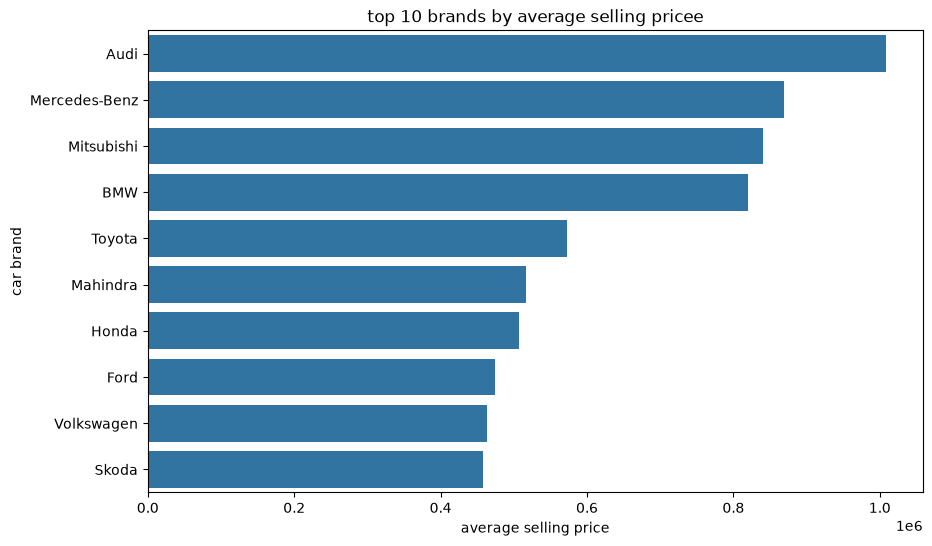

In [126]:
plt.figure(figsize=(10,6))
sns.barplot(
    x=top_10_brands.values,
    y=top_10_brands.index)
plt.title("top 10 brands by average selling pricee")
plt.xlabel("average selling price")
plt.ylabel("car brand")
plt.show()

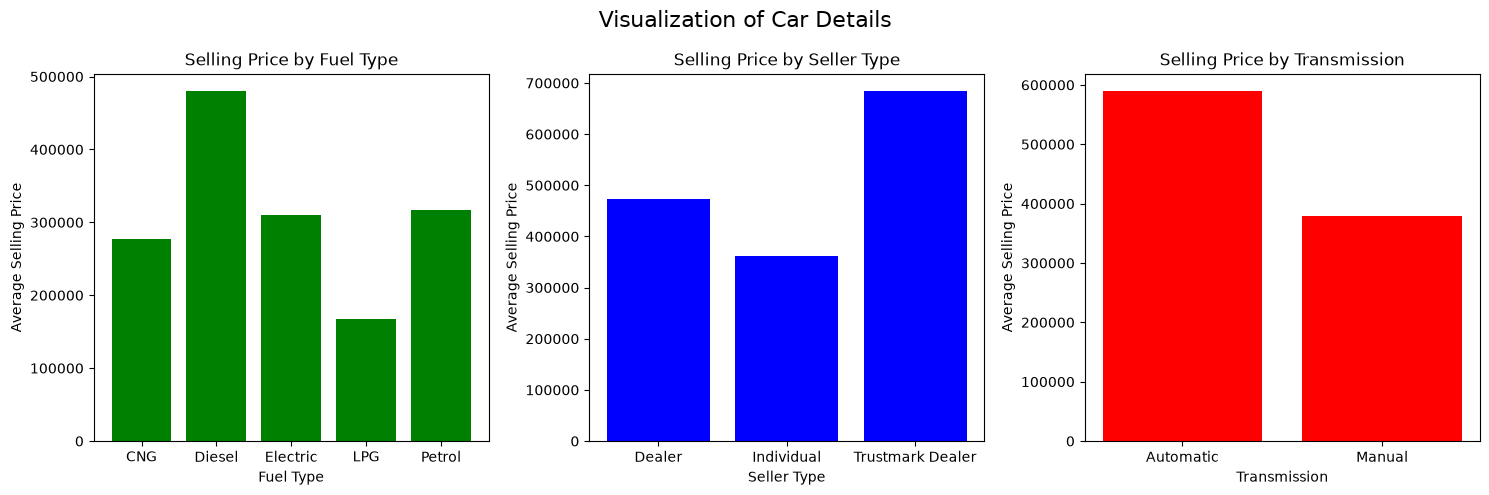

In [127]:


fig = plt.figure(figsize=(15, 5))

fig.suptitle("Visualization of Car Details", fontsize=16)

# First Chart - Fuel Type
plt.subplot(1, 3, 1)

fuel_data = df_clean.groupby("fuel")["selling_price"].mean()

plt.bar(fuel_data.index, fuel_data.values, color="green")

plt.xlabel("Fuel Type")
plt.ylabel("Average Selling Price")
plt.title("Selling Price by Fuel Type")


# Second Chart - Seller Type
plt.subplot(1, 3, 2)

seller_data = df_clean.groupby("seller_type")["selling_price"].mean()

plt.bar(seller_data.index, seller_data.values, color="blue")

plt.xlabel("Seller Type")
plt.ylabel("Average Selling Price")
plt.title("Selling Price by Seller Type")


# Third Chart - Transmission
plt.subplot(1, 3, 3)

trans_data = df_clean.groupby("transmission")["selling_price"].mean()

plt.bar(trans_data.index, trans_data.values, color="red")

plt.xlabel("Transmission")
plt.ylabel("Average Selling Price")
plt.title("Selling Price by Transmission")

plt.tight_layout()

plt.show()